# Time-Series Downsampling (LTTB / MinMaxLTTB)

**Family:** Interactive, animated & big data &nbsp;|&nbsp; **Library:** matplotlib / seaborn &nbsp;|&nbsp; **Level:** Intermediate

> *Interactive, animated & big data:* What-if sliders, linked views, animation and million-point rendering. Use these when exploration or motion adds understanding that a static chart cannot.

## Design purpose

Reduces a very long series (ticks, sensor readings, logs) to the number of points a screen can show, while keeping its visual shape. Taking every n-th point is fast but drops spikes and crashes that fall between the kept samples. LTTB keeps, in each bucket, the point that forms the largest triangle with its neighbours, so extremes survive. MinMaxLTTB first keeps each small bucket's minimum and maximum (cheap and vectorised), then runs LTTB on that much smaller set. It gives near-identical output an order of magnitude faster.

## When to use

- Plotting millions of points in a line chart, notebook, dashboard or web page
- Interactive charts that must re-render quickly while zooming
- Any series where rare spikes, outages or crashes must stay visible

## Avoid when

- Small series (draw every point)
- You need exact values or statistics; downsampling is for drawing, not for analysis
- Dense scatter data without an order (use datashader or hexbin instead)

## Alternatives

- Datashader line rendering (aggregate to pixels)
- Min/max envelope per pixel (M4 aggregation)
- OHLC bars or candlesticks at a coarser interval

## Design tips

- Target roughly 2 to 4 points per horizontal pixel of the final chart
- Re-downsample the visible window on zoom, rather than once for the whole series
- In Python, the tsdownsample package (Rust) implements MinMax, M4, LTTB and MinMaxLTTB
- Never use plain decimation on financial ticks; it can hide the very event you are looking for

## Example

1.5 million simulated ticks for one trading session, with fat-tailed moves, a 5% flash crash and recovery mid-afternoon, and a few single-tick bad prints. Each method reduces the series to 1,000 points; the right column zooms into the crash.

### Setup

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Library style: categorical colors in fixed order, recessive axes, hairline grid.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_CMAP = "Blues"      # sequential: one hue, light -> dark
DIV_CMAP = "RdBu_r"     # diverging: two opposite hues, neutral midpoint
GRAY = "#b8b7b1"        # de-emphasised marks
plt.rcParams.update({
    "figure.figsize": (8, 4.8), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "font.size": 10, "lines.linewidth": 2,
    "legend.frameon": False,
})

### Data

In [2]:
rng = np.random.default_rng(5)
N = 1_500_000                                   # ticks in one trading session
t = np.linspace(9.5, 16.0, N)                   # hours, 09:30 -> 16:00
steps = rng.standard_t(3, N) * 0.000008       # ~1.5% daily volatility
price = 100 * np.exp(np.cumsum(steps)) * (1 + rng.normal(0, 0.00008, N))   # + bid-ask bounce
crash = int(N * 0.62)                           # a flash crash: -5% in ~300 ticks, slow recovery
price[crash:crash + 300] *= np.linspace(1, 0.95, 300)
price[crash + 300:crash + 6300] *= np.linspace(0.95, 1, 6000)
for k in rng.choice(N, 4, replace=False):       # a few single-tick bad prints
    price[k] *= 1 + rng.choice([-1, 1]) * 0.02
df = pd.DataFrame({"hour": t, "price": price})
print(f"{len(df):,} ticks, low {price.min():.2f} at {t[price.argmin()]:.3f} h")

1,500,000 ticks, low 92.55 at 13.531 h


### Plot

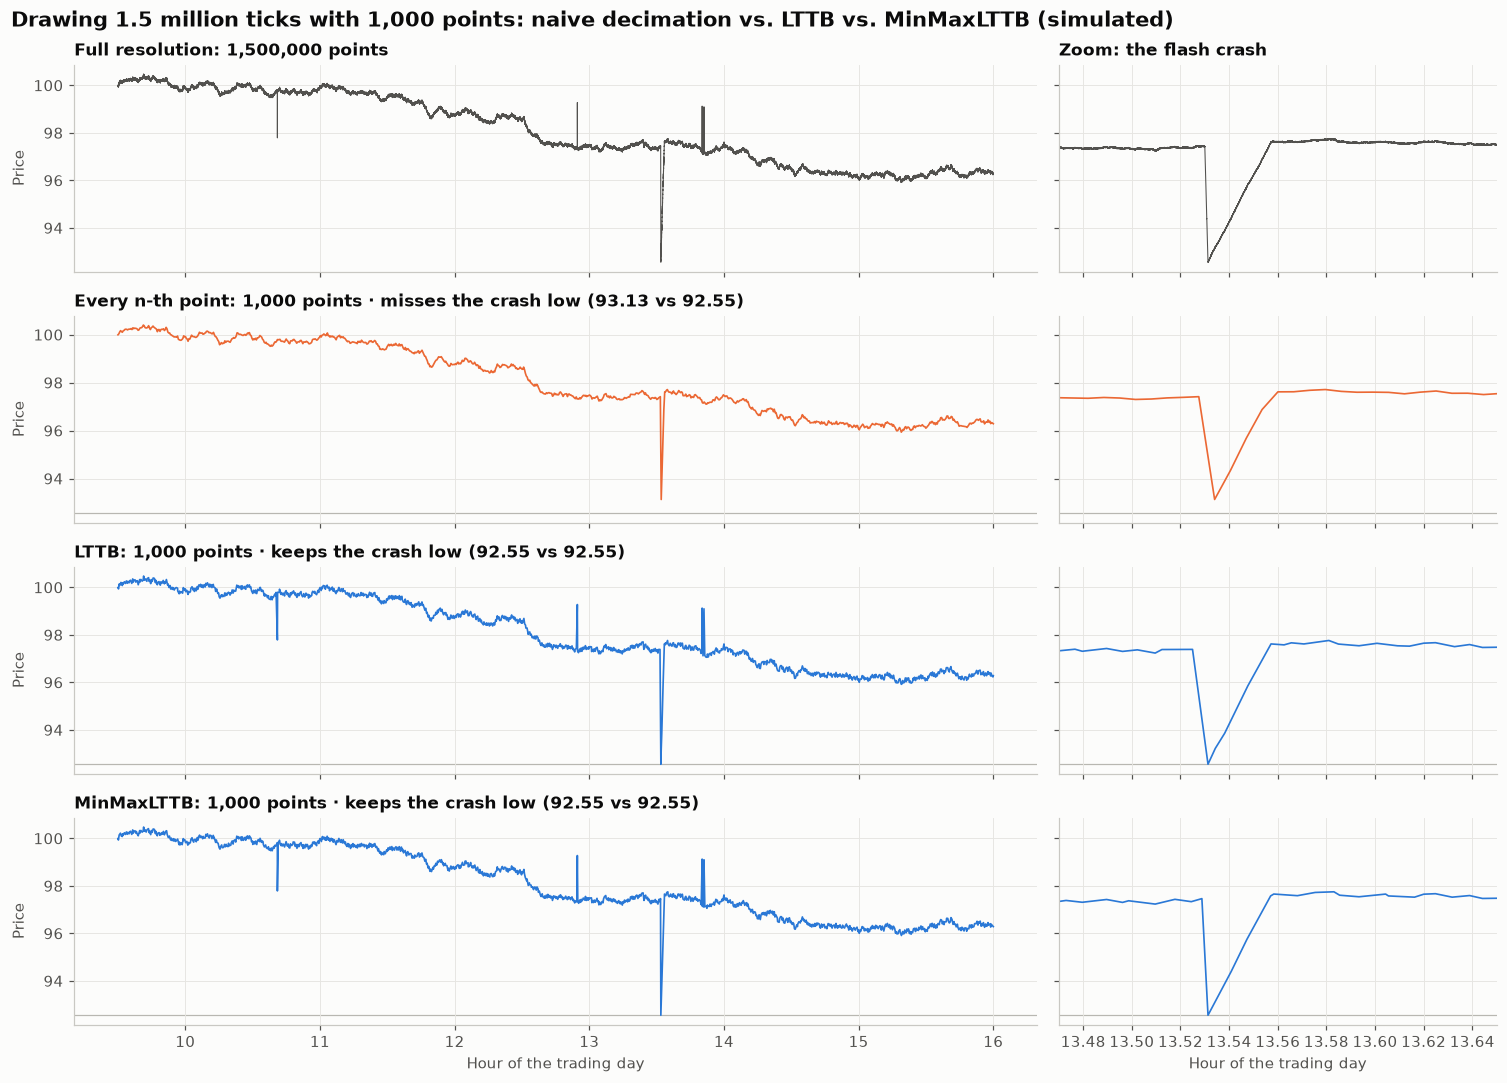

In [3]:
def every_nth(x, y, n_out):
    return np.linspace(0, len(x) - 1, n_out).astype(int)


def lttb(x, y, n_out):
    """Largest-Triangle-Three-Buckets (Steinarsson 2013): per bucket, keep the point that forms
    the largest triangle with the previously kept point and the next bucket's average."""
    n = len(x)
    if n_out >= n:
        return np.arange(n)
    edges = np.floor(np.linspace(1, n - 1, n_out - 1)).astype(int)   # n_out-2 interior buckets
    keep = np.empty(n_out, dtype=int)
    keep[0], keep[-1] = 0, n - 1
    a = 0
    for i in range(n_out - 2):
        lo, hi = edges[i], edges[i + 1]
        nlo, nhi = hi, (edges[i + 2] if i + 2 < len(edges) else n)
        cx, cy = x[nlo:nhi].mean(), y[nlo:nhi].mean()
        area = np.abs((x[a] - cx) * (y[lo:hi] - y[a]) - (x[a] - x[lo:hi]) * (cy - y[a]))
        a = lo + int(np.argmax(area))
        keep[i + 1] = a
    return keep


def minmax_lttb(x, y, n_out, ratio=4):
    """MinMaxLTTB (Van Der Donckt et al. 2023): keep each small bucket's min and max first
    (vectorised, cheap), then run LTTB on that much smaller candidate set."""
    n_buckets = n_out * ratio // 2
    usable = (len(x) - 2) // n_buckets * n_buckets
    block = y[1:1 + usable].reshape(n_buckets, -1)
    offs = np.arange(n_buckets) * block.shape[1] + 1
    cand = np.unique(np.concatenate([[0], offs + block.argmin(1), offs + block.argmax(1), [len(x) - 1]]))
    return cand[lttb(x[cand], y[cand], n_out)]


x, y = df["hour"].to_numpy(), df["price"].to_numpy()
N_OUT = 1_000
methods = {}
for name, fn in (("Every n-th point", every_nth), ("LTTB", lttb), ("MinMaxLTTB", minmax_lttb)):
    methods[name] = fn(x, y, N_OUT)   # time these with %timeit: MinMaxLTTB is several times faster

true_low = y.min()
zoom = (x[crash] - 0.06, x[crash] + 0.12)
fig, axes = plt.subplots(4, 2, figsize=(14, 10), sharex="col", sharey="row",
                         gridspec_kw={"width_ratios": [2.2, 1]})
rows = [("Full resolution", np.arange(len(x)))] + list(methods.items())
for r, (name, idx) in enumerate(rows):
    color = "#52514e" if r == 0 else (PALETTE[1] if name == "Every n-th point" else PALETTE[0])
    for c in range(2):
        ax = axes[r, c]
        ax.plot(x[idx], y[idx], color=color, linewidth=0.7 if r == 0 else 1.1, rasterized=(r == 0))
        if r > 0:
            ax.axhline(true_low, color="#b8b7b1", linewidth=0.8, zorder=0)
        if c == 1:
            ax.set_xlim(*zoom)
    low = y[idx].min()
    caught = "keeps" if abs(low - true_low) / true_low < 0.002 else "misses"
    label = (f"{name}: {len(idx):,} points" if r == 0 else
             f"{name}: {len(idx):,} points · {caught} the crash low ({low:.2f} vs {true_low:.2f})")
    axes[r, 0].set_title(label, fontsize=11)
    axes[r, 0].set_ylabel("Price")
axes[0, 1].set_title("Zoom: the flash crash", fontsize=11)
for ax in axes[-1]:
    ax.set_xlabel("Hour of the trading day")
fig.suptitle("Drawing 1.5 million ticks with 1,000 points: naive decimation vs. LTTB vs. MinMaxLTTB (simulated)",
             x=0.01, ha="left", fontsize=13.5, fontweight="bold")
fig.tight_layout()
plt.show()

## How to read it

The top row is the truth. Every n-th point (orange) loses all four single-tick bad prints and stops short of the crash low, so a reader would never know they happened. LTTB and MinMaxLTTB (blue) look almost identical to the full-resolution chart, crash low and bad prints included, from 0.07% of the points.

## Reference

This method comes from the research literature:

- Van Der Donckt, J., Van Der Donckt, J., Rademaker, M. & Van Hoecke, S. (2023). MinMaxLTTB: Leveraging MinMax-preselection to scale LTTB. IEEE VIS 2023 (Short Papers). <https://arxiv.org/abs/2305.00332>
- Steinarsson, S. (2013). Downsampling time series for visual representation. MSc thesis, University of Iceland.

---
Standalone script: [`lttb_downsampling.py`](lttb_downsampling.py) &nbsp;·&nbsp; [Catalogue](../../README.md) &nbsp;·&nbsp; [Gallery](../../gallery/index.html)